# Лабораторна робота № 4

## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Мета роботи:** порівняти дерево рішень (Decision Tree), випадковий ліс (Random Forest) та градієнтний
бустинг (XGBoost) на датасеті Annealing, дослідити вплив способу обробки пропусків, виконати підбір
гіперпараметрів без витоку даних (Optuna), неупереджено оцінити моделі вкладеною крос-валідацією,
статистично порівняти результати та інтерпретувати моделі (permutation importance, SHAP).

### Індивідуальний варіант

Номер у списку групи **N = 8**, отже **SEED = 42 + 8 = 50**. Цією константою ініціалізуються всі джерела
випадковості: поділ даних, крос-валідація, моделі та семплер Optuna.

### Джерело даних

Методичка пропонує завантажувати датасет через `fetch_openml(name='anneal', version=1)`. На момент виконання
роботи сервіс OpenML повертав помилку `HTTP 503 Service Temporarily Unavailable`, тому дані взято з
першоджерела, UCI Machine Learning Repository
([Annealing Data Set](https://archive.ics.uci.edu/dataset/3/annealing)), і збережено у `data/anneal.csv`.

Використано **повну версію з 898 спостережень** (файли `anneal.data` з 798 рядків і `anneal.test` зі 100 рядків),
що точно відповідає версії OpenML: той самий розмір, ті самі 38 ознак і той самий розподіл цільової змінної
(класи 3, 2, 5, U, 1; класу 4 у даних немає). Пропуски у файлі позначені символом `?`.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
import shap

N_STUDENT = 8
SEED = 42 + N_STUDENT
np.random.seed(SEED)
print('SEED =', SEED)

SEED = 50


In [2]:
# Версії бібліотек (фіксуються у requirements.txt)
import importlib.metadata as md

packages = ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn', 'xgboost', 'optuna', 'shap']
versions = {p: md.version(p) for p in packages}

with open('requirements.txt', 'w') as f:
    for p, v in versions.items():
        f.write(f'{p}=={v}\n')

pd.Series(versions, name='версія').to_frame()

,версія
numpy,2.5.3
pandas,3.0.6
scipy,1.18.1
matplotlib,3.11.2
scikit-learn,1.9.1
xgboost,3.4.1
optuna,5.0.0
shap,0.53.0


## 3.1 Первинний аналіз даних

In [3]:
df = pd.read_csv('data/anneal.csv')

# Числові ознаки за документацією датасету (anneal.names): решта є категоріальними
NUMERIC = ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']
for col in df.columns:
    if col not in NUMERIC:
        df[col] = df[col].astype('object')

X_full = df.drop(columns='class')
y_raw = df['class'].astype(str)

print('Спостережень:', df.shape[0], ' Ознак:', X_full.shape[1])
print('Типи ознак:', X_full.dtypes.value_counts().to_dict())
df.head(3)

Спостережень: 898  Ознак: 38
Типи ознак: {dtype('O'): 32, dtype('int64'): 4, dtype('float64'): 2}


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,...,s,p,shape,thick,width,len,oil,bore,packing,class
0,NaN,C,A,8,0,NaN,S,NaN,0,NaN,...,NaN,NaN,COIL,0.7,610.0,0,NaN,0,NaN,3
1,NaN,C,R,0,0,NaN,S,2.0,0,NaN,...,NaN,NaN,COIL,3.2,610.0,0,NaN,0,NaN,3
2,NaN,C,R,0,0,NaN,S,2.0,0,NaN,...,NaN,NaN,SHEET,0.7,1300.0,762,NaN,0,NaN,3


**Про типи ознак.** За документацією `anneal.names` неперервними є лише шість ознак:
`carbon`, `hardness`, `strength`, `thick`, `width`, `len`. Решта (включно з `formability`, `enamelability`,
`bore`, `packing`, які записані цифрами) це закодовані категорії, тому їх приведено до типу `object`
і далі вони підуть у one-hot кодування.

class
1      8
2     99
3    684
5     67
U     40
Name: count, dtype: int64

Частки:
class
1    0.0089
2    0.1102
3    0.7617
5    0.0746
U    0.0445
Name: count, dtype: float64


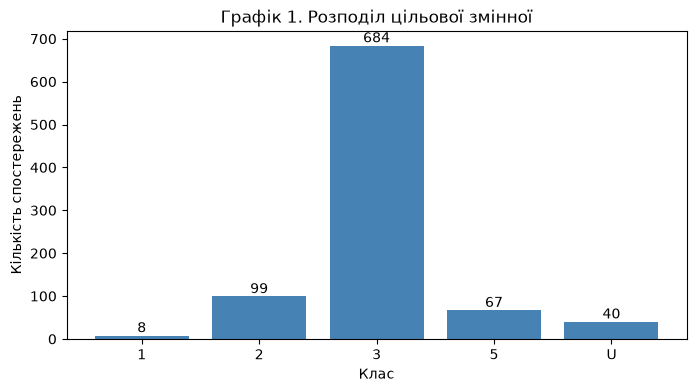

In [4]:
# Розподіл цільової змінної (графік 1)
class_counts = y_raw.value_counts().sort_index()
print(class_counts)
print('\nЧастки:')
print((class_counts / len(y_raw)).round(4))

plt.figure(figsize=(8, 4))
bars = plt.bar(class_counts.index, class_counts.values, color='steelblue')
plt.bar_label(bars)
plt.xlabel('Клас')
plt.ylabel('Кількість спостережень')
plt.title('Графік 1. Розподіл цільової змінної')
plt.show()

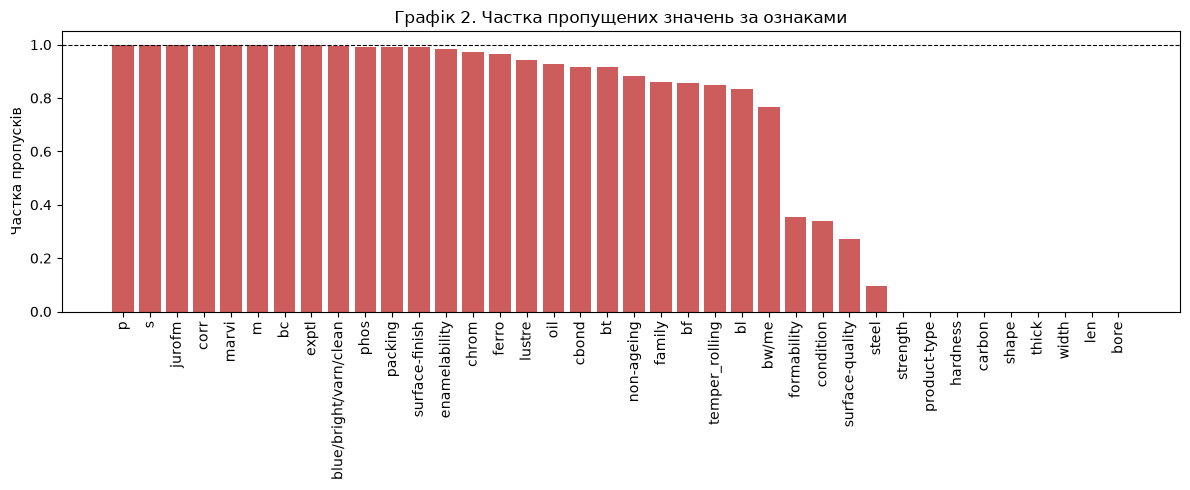

Повністю порожніх ознак: 6
Ознак без жодного пропуску: 9


In [5]:
# Частка пропусків за ознаками (графік 2)
missing_share = X_full.isna().mean().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
bars = plt.bar(range(len(missing_share)), missing_share.values, color='indianred')
plt.xticks(range(len(missing_share)), missing_share.index, rotation=90)
plt.ylabel('Частка пропусків')
plt.title('Графік 2. Частка пропущених значень за ознаками')
plt.axhline(1.0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

print('Повністю порожніх ознак:', int((missing_share == 1).sum()))
print('Ознак без жодного пропуску:', int((missing_share == 0).sum()))

In [6]:
# Видалення порожніх та константних ознак
empty_cols = [c for c in X_full.columns if X_full[c].isna().all()]
const_cols = [c for c in X_full.columns
              if c not in empty_cols and X_full[c].nunique(dropna=True) <= 1]

X = X_full.drop(columns=empty_cols + const_cols)

print(f'Повністю порожні ({len(empty_cols)}):', empty_cols)
print(f'\nКонстантні, тобто одне унікальне значення на всі спостереження ({len(const_cols)}):')
print(const_cols)
print('\nЗалишилось ознак:', X.shape[1])

Повністю порожні (6): ['m', 'marvi', 'corr', 'jurofm', 's', 'p']

Константні, тобто одне унікальне значення на всі спостереження (14):
['product-type', 'temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']

Залишилось ознак: 18


**Обґрунтування видалення.** Прибрано 20 ознак:

- 6 ознак **повністю порожні**: у них немає жодного спостереження, тому ні імпутувати, ні використати їх
  неможливо;
- 14 ознак **константні**: вони мають одне-єдине спостережуване значення (решта пропуски), наприклад `bc`
  має лише значення `Y` у 1 об'єкта з 898. Така ознака не несе інформації для розділення класів, бо після
  імпутації модою перетворюється на стовпець з однакових значень.

Важливо: для цих ознак сам **факт пропуску** теж не інформативний, бо він однаковий майже для всіх об'єктів.
Залишилось 18 ознак.

In [7]:
# Які з решти ознак мають пропуски
missing_kept = X.isna().mean().sort_values(ascending=False)
missing_kept = missing_kept[missing_kept > 0]
print(f'Ознак із пропусками: {len(missing_kept)} з {X.shape[1]}')
missing_kept.round(3).to_frame('частка пропусків')

Ознак із пропусками: 10 з 18


,частка пропусків
blue/bright/varn/clean,0.993
packing,0.990
enamelability,0.982
oil,0.929
family,0.860
bw/me,0.765
formability,0.354
condition,0.337
surface-quality,0.272
steel,0.096


### Аналіз механізму пропусків

Для п'яти ознак із найбільшою часткою пропусків будуємо таблицю спряженості «пропуск / не пропуск» на клас
і перевіряємо незалежність критерієм хі-квадрат. Нульова гіпотеза: факт пропуску не залежить від класу
(це відповідало б механізму MCAR).

In [8]:
rows = []
for col in missing_kept.head(5).index:
    table = pd.crosstab(X[col].isna(), y_raw)
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    rows.append({'Ознака': col,
                 'Частка пропусків': round(missing_kept[col], 3),
                 'chi2': round(chi2, 1),
                 'p-value': f'{p_value:.2e}',
                 'dof': dof,
                 'мін. очікувана частота': round(expected.min(), 2),
                 'Висновок': 'залежить від класу' if p_value < 0.05 else 'незалежний (MCAR)'})

missing_mechanism = pd.DataFrame(rows)
missing_mechanism

,Ознака,Частка пропусків,chi2,p-value,dof,мін. очікувана частота,Висновок
0,blue/bright/varn/clean,0.993,37.4,1.51e-07,4,0.05,залежить від класу
1,packing,0.990,2.8,5.84e-01,4,0.08,незалежний (MCAR)
2,enamelability,0.982,44.4,5.20e-09,4,0.14,залежить від класу
3,oil,0.929,24.5,6.26e-05,4,0.57,залежить від класу
4,family,0.860,463.7,4.63e-99,4,1.12,залежить від класу


In [9]:
# Детальніше для найсильнішого випадку
print('Таблиця спряженості для family (рядки: чи пропущено значення):')
print(pd.crosstab(X['family'].isna(), y_raw))
print('\nЧастка пропусків family у кожному класі:')
print(X['family'].isna().groupby(y_raw).mean().round(3))

Таблиця спряженості для family (рядки: чи пропущено значення):
class   1   2    3   5   U
family                    
False   2   0   46  67  11
True    6  99  638   0  29

Частка пропусків family у кожному класі:
class
1    0.750
2    1.000
3    0.933
5    0.000
U    0.725
Name: family, dtype: float64


**Висновок про механізм пропусків.**

*Що показано:* для п'яти ознак із найбільшою часткою пропусків перевірено, чи залежить факт пропуску від класу.

*Закономірність:* для чотирьох ознак із п'яти гіпотезу про незалежність рішуче відкинуто:
`family` (chi2 = 463.7, p = 4.6e-99), `enamelability` (p = 5.2e-09), `blue/bright/varn/clean` (p = 1.5e-07),
`oil` (p = 6.3e-05). Лише `packing` виглядає як MCAR (p = 0.58).

Найяскравіший випадок це `family`: у класі `5` значення присутнє **завжди** (0% пропусків), а в класі `2`
воно відсутнє **завжди** (100% пропусків). Тобто сам факт пропуску майже однозначно відокремлює клас `5`
від класу `2`.

*Чому так:* у документації датасету зазначено, що частина пропусків є **структурними**: ознака просто
не застосовна до цього типу сталі. Відсутність значення тут не є втратою інформації, вона сама
**є інформацією** про технологічний процес. Це механізм MAR або MNAR, але точно не MCAR.

*Як це впливає на подальші кроки:* якщо пропуски не MCAR, бінарні індикатори пропусків (варіант B) мають
покращити якість, бо вони зберігають цю інформацію, яку звичайна імпутація модою знищує. Саме це
перевіряється в розділі 3.3.

*Застереження:* мінімальна очікувана частота в таблицях спряженості становить 0.05-1.12, тобто менша за 5.
Для таких малих частот наближення хі-квадрат є грубим (методичка радить точний критерій Фішера).
Проте рівні значущості тут настільки екстремальні (до 1e-99), що висновок від цього не змінюється.

In [10]:
# Кодування цільової змінної цілими числами (цього вимагає XGBoost)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print('Відповідність міток:', dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))
print('Кількість об\'єктів кожного класу:', dict(zip(label_encoder.classes_, np.bincount(y))))

Відповідність міток: {'1': 0, '2': 1, '3': 2, '5': 3, 'U': 4}
Кількість об'єктів кожного класу: {'1': np.int64(8), '2': np.int64(99), '3': np.int64(684), '5': np.int64(67), 'U': np.int64(40)}


**Рішення щодо рідкісних класів.** Найменший клас `1` має лише 8 спостережень. Ми його **залишаємо** без
об'єднання з іншими з таких причин:

- класи відповідають різним станам сталі, тому об'єднання не має фізичного змісту;
- виключення класу змінило б постановку задачі й завищило метрики.

Наслідки для крос-валідації треба враховувати: після поділу 80/20 у тренувальній вибірці залишиться 6 об'єктів
класу `1`. Для зовнішньої 5-блочної крос-валідації цього вистачає (щонайменше 1 об'єкт на блок), а для
**внутрішньої** крос-валідації в Optuna беремо лише **3 блоки**, інакше тренувальна частина блоку може взагалі
не містити цього класу, і XGBoost завершиться помилкою. Macro F1 при цьому буде шумною метрикою саме через клас `1`:
кожен окремий об'єкт сильно змінює її значення.

## 3.2 Поділ даних і пайплайн обробки

Поділ стратифікований, 80% на навчання і 20% на тест. **Тестова вибірка використовується один раз**,
у розділі 3.6.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print('Train:', X_train.shape, ' Test:', X_test.shape)
pd.DataFrame({
    'train': pd.Series(np.bincount(y_train), index=label_encoder.classes_),
    'test': pd.Series(np.bincount(y_test), index=label_encoder.classes_),
})

Train: (718, 18)  Test: (180, 18)


,train,test
1,6,2
2,79,20
3,547,137
5,54,13
U,32,8


Будуємо два варіанти обробки:

- **Варіант A (базова імпутація):** числові ознаки заповнюються медіаною, категоріальні модою, далі one-hot.
- **Варіант B (імпутація з індикаторами):** те саме плюс бінарні ознаки-індикатори для кожної ознаки,
  що містила пропуски у тренувальних даних.

Уся обробка знаходиться **всередині `Pipeline`**. Це принципово: імпутер навчається тільки на тренувальній
частині кожного блоку крос-валідації, тому витоку даних немає.

*Примітка.* Починаючи зі scikit-learn 1.3, дерева й випадковий ліс уміють працювати з `NaN` нативно, як і
XGBoost. Імпутацію застосовано навмисно, щоб усі три моделі отримували однакові вхідні дані і порівняння було
контрольованим.

In [12]:
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'), make_column_selector()))
    return ColumnTransformer(transformers)


def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)


def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])


# скільки ознак дає кожен варіант обробки
for with_ind in (False, True):
    prep = build_preprocessor(with_ind).fit(X_train, y_train)
    print(f'Варіант {"B" if with_ind else "A"}: {len(prep.get_feature_names_out())} ознак після обробки')

Варіант A: 41 ознак після обробки
Варіант B: 51 ознак після обробки


## 3.3 Базові моделі з типовими гіперпараметрами

Оцінювання на тренувальній вибірці повторною стратифікованою крос-валідацією (5 блоків x 3 повторення).
**Усі моделі й варіанти оцінюються на одному й тому самому об'єкті `cv`**, що потрібно для парного
статистичного порівняння в розділі 3.5.

In [13]:
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

MODELS = ['DT', 'RF', 'XGB']
MODEL_NAMES = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}

cv_raw = {}     # сирі значення по блоках, знадобляться для тесту Наде-Бенжіо


def run_cv(with_indicators):
    rows = []
    for name in MODELS:
        res = cross_validate(build_pipeline(name, with_indicators), X_train, y_train,
                             cv=cv, scoring=scoring)
        variant = 'B' if with_indicators else 'A'
        cv_raw[(name, variant)] = res['test_f1m']
        rows.append({
            'Модель': MODEL_NAMES[name],
            'accuracy': f"{res['test_acc'].mean():.4f} ± {res['test_acc'].std():.4f}",
            'macro F1': f"{res['test_f1m'].mean():.4f} ± {res['test_f1m'].std():.4f}",
            'balanced accuracy': f"{res['test_bacc'].mean():.4f} ± {res['test_bacc'].std():.4f}",
        })
    return pd.DataFrame(rows)


table1 = run_cv(with_indicators=False)
print('Таблиця 1. Крос-валідація, варіант A (базова імпутація), типові параметри')
table1

Таблиця 1. Крос-валідація, варіант A (базова імпутація), типові параметри


,Модель,accuracy,macro F1,balanced accuracy
0,Decision Tree,0.9526 ± 0.0111,0.9229 ± 0.0547,0.9233 ± 0.0629
1,Random Forest,0.9452 ± 0.0138,0.9298 ± 0.0156,0.9286 ± 0.0281
2,XGBoost,0.9508 ± 0.0133,0.9168 ± 0.0530,0.9109 ± 0.0530


In [14]:
table2 = run_cv(with_indicators=True)
print('Таблиця 2. Крос-валідація, варіант B (з індикаторами пропусків), типові параметри')
table2

Таблиця 2. Крос-валідація, варіант B (з індикаторами пропусків), типові параметри


,Модель,accuracy,macro F1,balanced accuracy
0,Decision Tree,0.9930 ± 0.0057,0.9903 ± 0.0088,0.9933 ± 0.0109
1,Random Forest,0.9921 ± 0.0056,0.9864 ± 0.0125,0.9845 ± 0.0150
2,XGBoost,0.9907 ± 0.0070,0.9842 ± 0.0142,0.9816 ± 0.0190


In [15]:
# Наочне порівняння A і B за macro F1
comparison = pd.DataFrame({
    'Варіант A': [cv_raw[(m, 'A')].mean() for m in MODELS],
    'Варіант B': [cv_raw[(m, 'B')].mean() for m in MODELS],
}, index=[MODEL_NAMES[m] for m in MODELS])
comparison['Приріст'] = comparison['Варіант B'] - comparison['Варіант A']
comparison.round(4)

,Варіант A,Варіант B,Приріст
Decision Tree,0.9229,0.9903,0.0673
Random Forest,0.9298,0.9864,0.0567
XGBoost,0.9168,0.9842,0.0675


**Висновок за таблицями 1 і 2.**

*Що показано:* якість трьох моделей із типовими гіперпараметрами на повторній крос-валідації (5 блоків x 3 повторення)
для двох варіантів обробки пропусків.

*Закономірність:* індикатори пропусків дають великий приріст **усім трьом моделям**:

| Модель | macro F1, варіант A | macro F1, варіант B | Приріст |
|---|---|---|---|
| Decision Tree | 0.9229 ± 0.0547 | **0.9903 ± 0.0088** | +0.0673 |
| Random Forest | 0.9298 ± 0.0156 | 0.9864 ± 0.0125 | +0.0567 |
| XGBoost | 0.9168 ± 0.0530 | 0.9842 ± 0.0142 | +0.0675 |

Разом із середнім сильно впало й стандартне відхилення: у дерева з 0.055 до 0.009, тобто результат став
не лише кращим, а й значно стабільнішим.

*Чому так:* це прямий наслідок аналізу з розділу 3.1. Пропуски не є MCAR, тому індикатор `missingindicator_family`
фактично кодує технологічну ознаку «цей тип сталі не має параметра family». У варіанті A ця інформація
знищується: пропуск заповнюється модою і стає невідрізнюваним від справжнього значення.

*Як це впливає на подальші кроки:* оптимізацію гіперпараметрів і всі подальші експерименти виконуємо
**тільки для варіанту B**. Водночас видно ефект стелі: accuracy вже на рівні 0.99, тому різниці між моделями
мізерні (0.9842 проти 0.9903) і можуть бути шумом. Саме тому потрібна статистична перевірка в розділі 3.5.

## 3.4 Підбір гіперпараметрів за допомогою Optuna

Оптимізація виконується **для варіанту B**. У цільову функцію передається **весь пайплайн** (обробка плюс
модель), а не заздалегідь оброблені дані: інакше імпутер побачив би валідаційні блоки і виник би витік даних.

Внутрішня крос-валідація має 3 блоки через рідкісний клас `1` (див. розділ 3.1).

In [16]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical(
                'class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }


def tune(name, X_tr, y_tr, n_trials=30):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()

    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

### Вкладена крос-валідація

Зовнішній цикл (5 блоків) оцінює якість, внутрішній підбирає гіперпараметри **лише на тренувальній частині
кожного зовнішнього блоку**. Так ми оцінюємо не конкретну модель, а **всю процедуру** «підбери параметри і навчи
модель», і ця оцінка не є оптимістично зміщеною.

Цей крок найдовший: 3 моделі x 5 зовнішніх блоків x 30 trials. Разом близько 5-6 хвилин.

In [17]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

nested_scores = {}
for name in MODELS:
    scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        scores.append(f1_score(y_va, model.predict(X_va), average='macro'))
    nested_scores[name] = np.array(scores)
    print(f'{MODEL_NAMES[name]:15s} вкладена CV macro F1 = {np.mean(scores):.4f} ± {np.std(scores):.4f}')

Decision Tree   вкладена CV macro F1 = 0.9791 ± 0.0127


Random Forest   вкладена CV macro F1 = 0.9819 ± 0.0104


XGBoost         вкладена CV macro F1 = 0.9852 ± 0.0129


In [18]:
# Одна "звичайна" оптимізація на всій тренувальній вибірці -> фінальні моделі
studies = {}
for name in MODELS:
    studies[name] = tune(name, X_train, y_train)
    print(f'{MODEL_NAMES[name]:15s} best_value = {studies[name].best_value:.4f}')

Decision Tree   best_value = 0.8949


Random Forest   best_value = 0.9231


XGBoost         best_value = 0.9157


In [19]:
table3 = pd.DataFrame([{
    'Модель': MODEL_NAMES[name],
    'Вкладена CV (macro F1)': f'{nested_scores[name].mean():.4f} ± {nested_scores[name].std():.4f}',
    'study.best_value': round(studies[name].best_value, 4),
    'Різниця (best_value - nested)': round(studies[name].best_value - nested_scores[name].mean(), 4),
} for name in MODELS])
print('Таблиця 3. Вкладена крос-валідація проти best_value')
table3

Таблиця 3. Вкладена крос-валідація проти best_value


,Модель,Вкладена CV (macro F1),study.best_value,Різниця (best_value - nested)
0,Decision Tree,0.9791 ± 0.0127,0.8949,-0.0843
1,Random Forest,0.9819 ± 0.0104,0.9231,-0.0589
2,XGBoost,0.9852 ± 0.0129,0.9157,-0.0695


In [20]:
# Додатково: оцінимо НАЛАШТОВАНІ моделі тією самою повторною крос-валідацією, що й у п. 3.3.
# Ця оцінка є оптимістично зміщеною (параметри підбирались на цих самих даних),
# зате вона порівнянна з таблицею 2 і показує чистий приріст від оптимізації.
tuned_cv = {}
rows = []
for name in MODELS:
    res = cross_validate(build_pipeline(name, True, studies[name].best_params),
                         X_train, y_train, cv=cv, scoring=scoring)
    tuned_cv[name] = res['test_f1m']
    rows.append({
        'Модель': MODEL_NAMES[name],
        'Типові параметри (5x3 CV)': round(cv_raw[(name, 'B')].mean(), 4),
        'Після Optuna (5x3 CV, зміщена)': round(res['test_f1m'].mean(), 4),
        'Приріст від оптимізації': round(res['test_f1m'].mean() - cv_raw[(name, 'B')].mean(), 4),
        'Вкладена CV (неупереджена)': round(nested_scores[name].mean(), 4),
        'best_value (3 блоки)': round(studies[name].best_value, 4),
    })
pd.DataFrame(rows)

,Модель,Типові параметри (5x3 CV),"Після Optuna (5x3 CV, зміщена)",Приріст від оптимізації,Вкладена CV (неупереджена),best_value (3 блоки)
0,Decision Tree,0.9903,0.9903,0.0000,0.9791,0.8949
1,Random Forest,0.9864,0.9869,0.0005,0.9819,0.9231
2,XGBoost,0.9842,0.9788,-0.0054,0.9852,0.9157


**Висновок за таблицею 3.**

*Що показано:* неупереджена оцінка вкладеної крос-валідації, значення `study.best_value` та, у додатковій таблиці,
оцінка налаштованих моделей тією самою повторною крос-валідацією, що й у розділі 3.3.

| Модель | Вкладена CV | best_value | Типові параметри (5x3) | Після Optuna (5x3) |
|---|---|---|---|---|
| Decision Tree | 0.9791 ± 0.0127 | 0.8949 | 0.9903 | 0.9903 |
| Random Forest | 0.9819 ± 0.0104 | 0.9231 | 0.9864 | 0.9869 |
| XGBoost | 0.9852 ± 0.0129 | 0.9157 | 0.9842 | 0.9788 |

*Закономірність:* `best_value` виявився **нижчим** за вкладену крос-валідацію (на 0.06-0.08), хоча теорія
передбачає протилежне: вибір максимуму серед 30 зашумлених оцінок має давати оптимістичне зміщення.

*Чому так:* ці два числа отримані за **різними протоколами** і напряму не порівнюються.
`best_value` це середнє macro F1 на **внутрішній 3-блочній** крос-валідації, яку ми змушені використовувати
через клас `1` із шістьма об'єктами. У 3 блоках кожна валідаційна частина містить близько 2 таких об'єктів,
а тренувальна лише 4, тому модель часто не розпізнає цей клас і macro F1 втрачає до 0.2 на одному блоці.
У зовнішньому 5-блочному циклі тренувальна частина більша, і той самий клас розпізнається краще.
Тобто ефект протоколу тут перекриває ефект оптимістичного зміщення.

Коректно порівнювати можна дві **останні** колонки: оцінка налаштованої моделі на тих самих даних, де
підбирались параметри (0.9903 у дерева), проти неупередженої вкладеної оцінки (0.9791). Різниця +0.011
і є тим самим оптимістичним зміщенням. Воно невелике лише тому, що працює ефект стелі.

*Як це впливає на вибір:* звітувати `best_value` як оцінку якості не можна в жодному разі. Приріст від
оптимізації тут практично нульовий (0.0000 у дерева, +0.0005 у лісу, -0.0054 у XGBoost): типові параметри
вже дають майже стелю, а Optuna максимізувала іншу, шумнішу цільову функцію (3-блочну), тому могла
навіть трохи зіпсувати результат.

In [21]:
table4 = pd.DataFrame([{'Модель': MODEL_NAMES[name], **studies[name].best_params} for name in MODELS])
print('Таблиця 4. Найкращі гіперпараметри, знайдені Optuna')
table4.set_index('Модель').T

Таблиця 4. Найкращі гіперпараметри, знайдені Optuna


Модель,Decision Tree,Random Forest,XGBoost
max_depth,15,25,7
min_samples_split,2.0,NaN,NaN
min_samples_leaf,1.0,1.0,NaN
class_weight,NaN,NaN,NaN
n_estimators,NaN,150.0,186.0
max_features,NaN,sqrt,NaN
learning_rate,NaN,NaN,0.235286
subsample,NaN,NaN,0.702753
colsample_bytree,NaN,NaN,0.760062
min_child_weight,NaN,NaN,1.2287


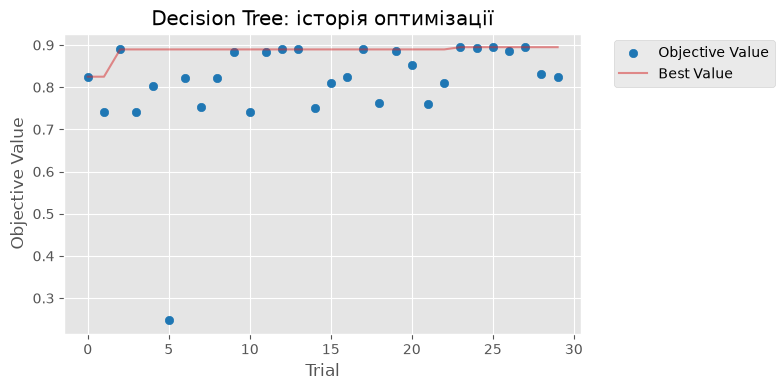

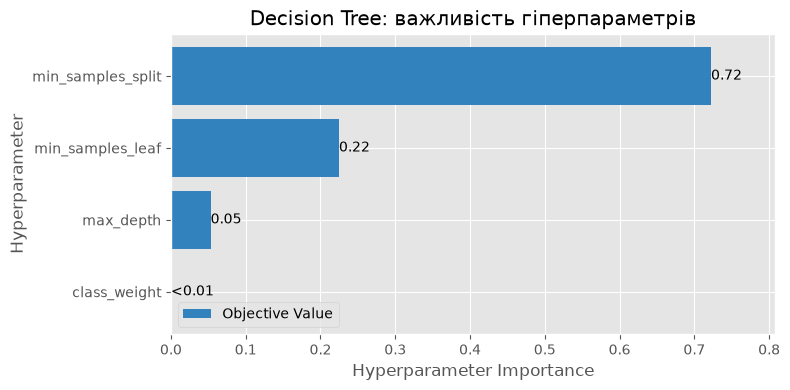

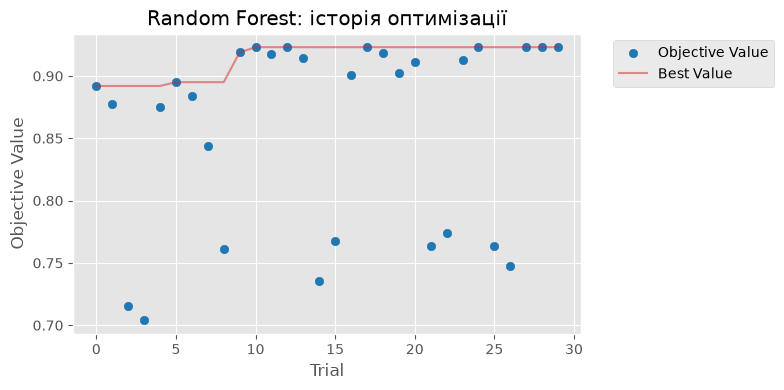

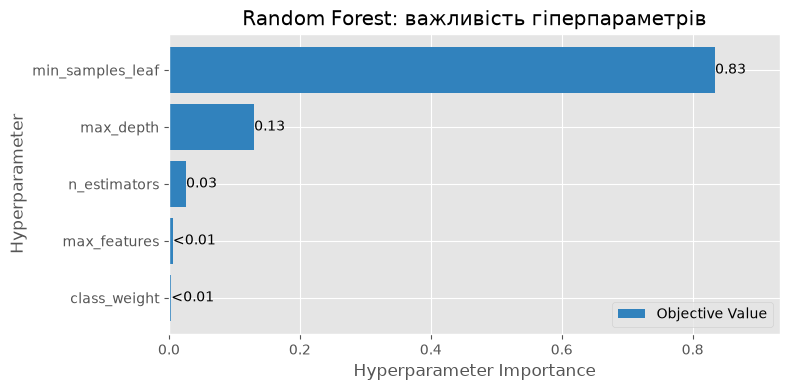

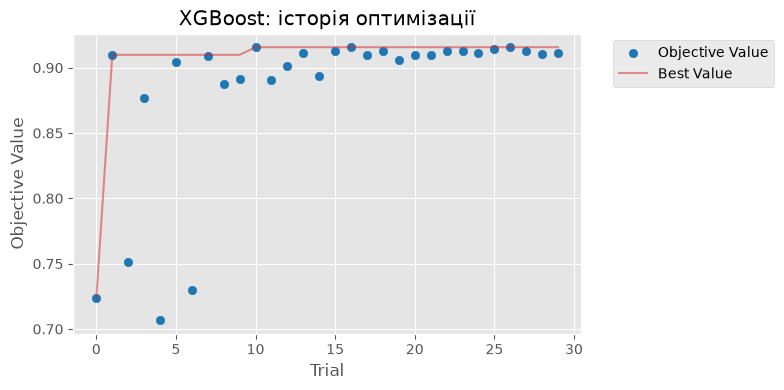

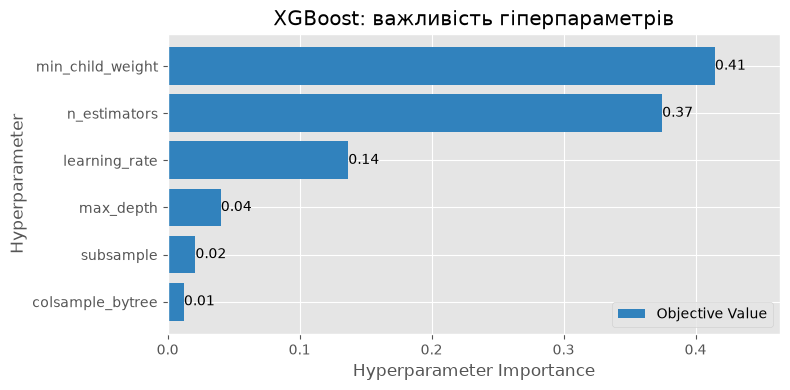

In [22]:
# Графік 3. Історія оптимізації та важливість гіперпараметрів
# (функції optuna.visualization.matplotlib самі створюють фігуру і повертають Axes)
for name in MODELS:
    ax = plot_optimization_history(studies[name])
    ax.set_title('', loc='left')   # прибираємо власний заголовок optuna
    ax.set_title(f'{MODEL_NAMES[name]}: історія оптимізації')
    ax.figure.set_size_inches(8, 4)
    plt.tight_layout()
    plt.show()

    ax = plot_param_importances(studies[name])
    ax.set_title('', loc='left')
    ax.set_title(f'{MODEL_NAMES[name]}: важливість гіперпараметрів')
    ax.figure.set_size_inches(8, 4)
    plt.tight_layout()
    plt.show()

**Висновок за графіком 3.**

*Що показано:* історія 30 випробувань Optuna та важливість гіперпараметрів для кожної моделі.

*Закономірність:* оптимізація збіглася дуже швидко. У дерева найкраще значення (близько 0.89) досягнуто вже
на 3-му випробуванні, далі крива найкращого значення майже горизонтальна. Окремі випробування провалюються
дуже глибоко (одне дало 0.25), що відповідає явно невдалим комбінаціям, наприклад надто великому
`min_samples_leaf` при класі з 6 об'єктів.

Важливість гіперпараметрів:
- **Decision Tree:** `min_samples_split` 0.72, `min_samples_leaf` 0.22, `max_depth` 0.05, `class_weight` менше 0.01;
- **Random Forest:** `min_samples_leaf` 0.83, `max_depth` 0.13, решта менше 0.03;
- **XGBoost:** `min_child_weight` 0.41, `n_estimators` 0.37, `learning_rate` 0.14.

*Чому так:* усі три моделі найчутливіші до параметрів, що обмежують **мінімальний розмір листка**.
Це прямий наслідок дисбалансу: клас `1` має лише 6 об'єктів у тренувальній вибірці, тому будь-яка вимога
«не менше ніж k об'єктів у листку» просто забороняє моделі виділити цей клас, і macro F1 різко падає.
Натомість `class_weight` виявився майже неважливим, бо на цьому датасеті класи й так добре розділяються
структурою ознак.

*Як це впливає на вибір:* 30 випробувань достатньо, збільшувати бюджет немає сенсу. Якби довелось звужувати
простір пошуку, варто фіксувати `min_samples_leaf = 1` і витрачати бюджет на інші параметри.

In [23]:
# Фінальні моделі: варіант B, найкращі параметри, навчання на всій тренувальній вибірці
final_models = {name: build_pipeline(name, True, studies[name].best_params).fit(X_train, y_train)
                for name in MODELS}
print('Фінальні моделі навчено:', list(final_models))

Фінальні моделі навчено: ['DT', 'RF', 'XGB']


## 3.5 Статистичне порівняння (скоригований t-тест Наде-Бенжіо)

Блоки крос-валідації перетинаються між собою тренувальними даними, тому оцінки не є незалежними, і звичайний
парний t-тест занижує дисперсію (дає завищену значущість). Поправка Наде-Бенжіо збільшує оцінку дисперсії
на множник, що враховує відношення розмірів валідаційної та тренувальної частин:

```
t = mean(d) / sqrt( var(d) * (1/(k*r) + n_test/n_train) ),   ступені свободи: k*r - 1
```

де `d` це різниці macro F1 двох моделей на одних і тих самих блоках.

In [24]:
def corrected_t_test(scores_a, scores_b, n_splits=5, n_repeats=3, test_ratio=1 / 4):
    # test_ratio = n_test / n_train; для 5 блоків це (1/5) / (4/5) = 1/4
    d = np.asarray(scores_a) - np.asarray(scores_b)
    n = n_splits * n_repeats
    d_mean = d.mean()
    d_var = d.var(ddof=1)
    if d_var == 0:
        return d_mean, np.nan, np.nan
    t_stat = d_mean / np.sqrt(d_var * (1 / n + test_ratio))
    p_value = 2 * stats.t.sf(abs(t_stat), df=n - 1)
    return d_mean, t_stat, p_value


rows = []
# 1) варіант B проти варіанту A для кожної моделі
for name in MODELS:
    d_mean, t_stat, p_value = corrected_t_test(cv_raw[(name, 'B')], cv_raw[(name, 'A')])
    rows.append({'Порівняння': f'{MODEL_NAMES[name]}: B проти A',
                 'd (сер. різниця)': round(d_mean, 4),
                 't': round(t_stat, 3),
                 'p': f'{p_value:.4f}',
                 'Висновок при alpha=0.05': 'різниця значуща' if p_value < 0.05 else 'різниця не значуща'})

# 2) дві найкращі моделі у варіанті B
best_two = sorted(MODELS, key=lambda m: cv_raw[(m, 'B')].mean(), reverse=True)[:2]
d_mean, t_stat, p_value = corrected_t_test(cv_raw[(best_two[0], 'B')], cv_raw[(best_two[1], 'B')])
rows.append({'Порівняння': f'{MODEL_NAMES[best_two[0]]} проти {MODEL_NAMES[best_two[1]]} (варіант B)',
             'd (сер. різниця)': round(d_mean, 4),
             't': round(t_stat, 3),
             'p': f'{p_value:.4f}',
             'Висновок при alpha=0.05': 'різниця значуща' if p_value < 0.05 else 'різниця не значуща'})

table5 = pd.DataFrame(rows)
print('Таблиця 5. Скоригований t-тест Наде-Бенжіо')
table5

Таблиця 5. Скоригований t-тест Наде-Бенжіо


,Порівняння,d (сер. різниця),t,p,Висновок при alpha=0.05
0,Decision Tree: B проти A,0.0673,1.967,0.0693,різниця не значуща
1,Random Forest: B проти A,0.0567,4.942,0.0002,різниця значуща
2,XGBoost: B проти A,0.0675,1.967,0.0693,різниця не значуща
3,Decision Tree проти Random Forest (варіант B),0.0038,0.663,0.5180,різниця не значуща


In [25]:
# Для порівняння: що дав би звичайний (некоригований) парний t-тест
for name in MODELS:
    d = cv_raw[(name, 'B')] - cv_raw[(name, 'A')]
    t_naive, p_naive = stats.ttest_rel(cv_raw[(name, 'B')], cv_raw[(name, 'A')])
    _, _, p_corrected = corrected_t_test(cv_raw[(name, 'B')], cv_raw[(name, 'A')])
    print(f'{MODEL_NAMES[name]:15s} звичайний t-тест p={p_naive:.6f}   скоригований p={p_corrected:.4f}')

Decision Tree   звичайний t-тест p=0.000753   скоригований p=0.0693
Random Forest   звичайний t-тест p=0.000000   скоригований p=0.0002
XGBoost         звичайний t-тест p=0.000752   скоригований p=0.0693


**Висновок за таблицею 5.**

*Що показано:* скоригований t-тест Наде-Бенжіо на 15 однакових блоках крос-валідації.

| Порівняння | d | t | p | Висновок |
|---|---|---|---|---|
| Decision Tree: B проти A | 0.0673 | 1.967 | 0.0693 | не значуща |
| Random Forest: B проти A | 0.0567 | 4.942 | **0.0002** | **значуща** |
| XGBoost: B проти A | 0.0675 | 1.967 | 0.0693 | не значуща |
| Decision Tree проти Random Forest (B) | 0.0038 | 0.663 | 0.5180 | не значуща |

*Закономірність і чому так:* попри те, що середній приріст від індикаторів у дерева і XGBoost навіть
**більший**, ніж у лісу (0.067 проти 0.057), значущою виявилась лише перевага у випадкового лісу.
Причина в дисперсії різниць: у лісу стандартне відхилення різниць 0.020, а в дерева і XGBoost 0.061,
тобто втричі більше. Нестабільні моделі на окремих блоках то виграють багато, то майже нічого,
і при 15 блоках цього не вистачає для значущості на рівні alpha = 0.05.

(Майже однакові t у дерева і XGBoost, 1.9668 і 1.9672, це збіг: у них близькі і середні різниці, і дисперсії.)

Порівняння двох найкращих моделей у варіанті B (дерево проти лісу) дає p = 0.52, тобто **різниці між моделями
немає**. Це прямий наслідок ефекту стелі.

*Навіщо поправка:* звичайний парний t-тест дав би для дерева p = 0.00075 замість 0.069, тобто в 90 разів
менше, і ми б помилково оголосили різницю значущою. Блоки крос-валідації перетинаються тренувальними даними,
їхні оцінки корельовані, і поправка Наде-Бенжіо враховує це, збільшуючи оцінку дисперсії на множник
`1/(k*r) + n_test/n_train`.

*Як це впливає на вибір:* формально статистика дозволяє стверджувати лише те, що індикатори допомагають
випадковому лісу. Для решти моделей приріст великий за величиною, але нестабільний, тож його варто вважати
правдоподібним, а не доведеним.

## 3.6 Фінальна оцінка на тестовій вибірці

Тестова вибірка відкривається вперше і лише один раз.

In [26]:
table6 = pd.DataFrame([{
    'Модель': MODEL_NAMES[name],
    'accuracy': accuracy_score(y_test, final_models[name].predict(X_test)),
    'macro F1': f1_score(y_test, final_models[name].predict(X_test), average='macro'),
    'balanced accuracy': balanced_accuracy_score(y_test, final_models[name].predict(X_test)),
} for name in MODELS]).round(4)
print('Таблиця 6. Якість фінальних моделей на тестовій вибірці')
table6

Таблиця 6. Якість фінальних моделей на тестовій вибірці


,Модель,accuracy,macro F1,balanced accuracy
0,Decision Tree,0.9944,0.9326,0.9000
1,Random Forest,0.9889,0.9270,0.8985
2,XGBoost,0.9889,0.9270,0.8985


In [27]:
best_name = MODELS[int(np.argmax([f1_score(y_test, final_models[m].predict(X_test), average='macro')
                                  for m in MODELS]))]
print('Найкраща модель на тесті:', MODEL_NAMES[best_name])
print('\nclassification_report:')
print(classification_report(y_test, final_models[best_name].predict(X_test),
                            target_names=label_encoder.classes_, zero_division=0))

Найкраща модель на тесті: Decision Tree

classification_report:
              precision    recall  f1-score   support

           1       1.00      0.50      0.67         2
           2       1.00      1.00      1.00        20
           3       0.99      1.00      1.00       137
           5       1.00      1.00      1.00        13
           U       1.00      1.00      1.00         8

    accuracy                           0.99       180
   macro avg       1.00      0.90      0.93       180
weighted avg       0.99      0.99      0.99       180



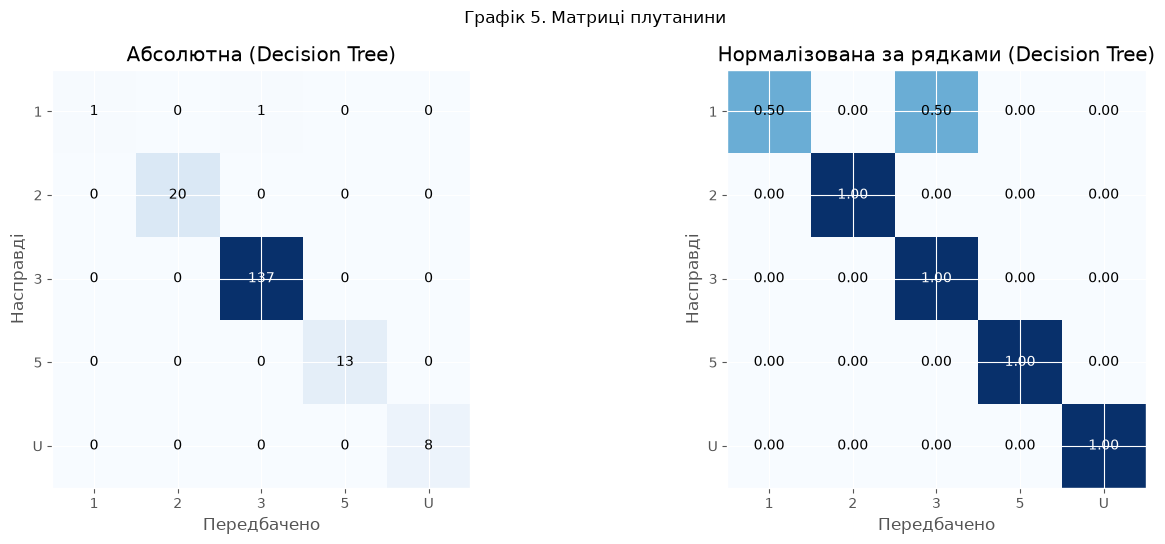

In [28]:
# Графік 5. Матриці плутанини найкращої моделі
y_pred_best = final_models[best_name].predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, matrix, title, fmt in [(axes[0], cm, 'Абсолютна', 'd'),
                               (axes[1], cm_norm, 'Нормалізована за рядками', '.2f')]:
    im = ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(label_encoder.classes_)))
    ax.set_xticklabels(label_encoder.classes_)
    ax.set_yticks(range(len(label_encoder.classes_)))
    ax.set_yticklabels(label_encoder.classes_)
    ax.set_xlabel('Передбачено')
    ax.set_ylabel('Насправді')
    ax.set_title(f'{title} ({MODEL_NAMES[best_name]})')
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = format(matrix[i, j], fmt)
            ax.text(j, i, value, ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.max() / 2 else 'black')
plt.suptitle('Графік 5. Матриці плутанини')
plt.tight_layout()
plt.show()

**Висновок за таблицею 6 і графіком 5.**

*Що показано:* якість фінальних моделей на тестовій вибірці, яку жодна з них раніше не бачила.

| Модель | accuracy | macro F1 | balanced accuracy |
|---|---|---|---|
| Decision Tree | **0.9944** | **0.9326** | **0.9000** |
| Random Forest | 0.9889 | 0.9270 | 0.8985 |
| XGBoost | 0.9889 | 0.9270 | 0.8985 |

*Закономірність:* accuracy на тесті навіть вища за крос-валідаційну (0.9944 проти 0.9930), а macro F1 помітно
нижча (0.9326 проти 0.9903). Матриця плутанини пояснює цей розрив повністю: з 180 тестових об'єктів модель
помилилась **рівно один раз**, сплутавши об'єкт класу `1` із класом `3`.

*Чому так:* у тесті лише **2 об'єкти класу `1`**. Одна помилка дає recall 0.50 для цього класу, а отже його
F1 = 0.67. Macro F1 усереднює по класах з однаковою вагою, тому єдина помилка коштує близько 0.07 загальної
метрики. Accuracy ж цю помилку майже не помічає, бо 179 з 180 правильні. Це класична ситуація
з мікроскопічним класом: метрика на тесті визначається буквально одним об'єктом і має величезну дисперсію.

Решта класів розпізнається ідеально: класи `2`, `3`, `5` і `U` мають recall 1.00.

*Як це впливає на вибір:* різниця між трьома моделями на тесті становить одну помилку, тобто обирати модель
за тестом тут немає сенсу. Для надійного висновку треба спиратись на крос-валідацію та статистичні тести.

## 3.7 Інтерпретація: важливість ознак

Рахуємо два види важливості:

1. **MDI** (`feature_importances_`): середнє зменшення неоднорідності. Обчислюється на **оброблених** ознаках,
   тобто після one-hot та з індикаторами пропусків.
2. **Permutation importance** на тестовій вибірці: наскільки падає macro F1, якщо випадково перемішати значення
   однієї ознаки. Застосовується до **всього пайплайну**, тобто рахується на початкових 18 ознаках.

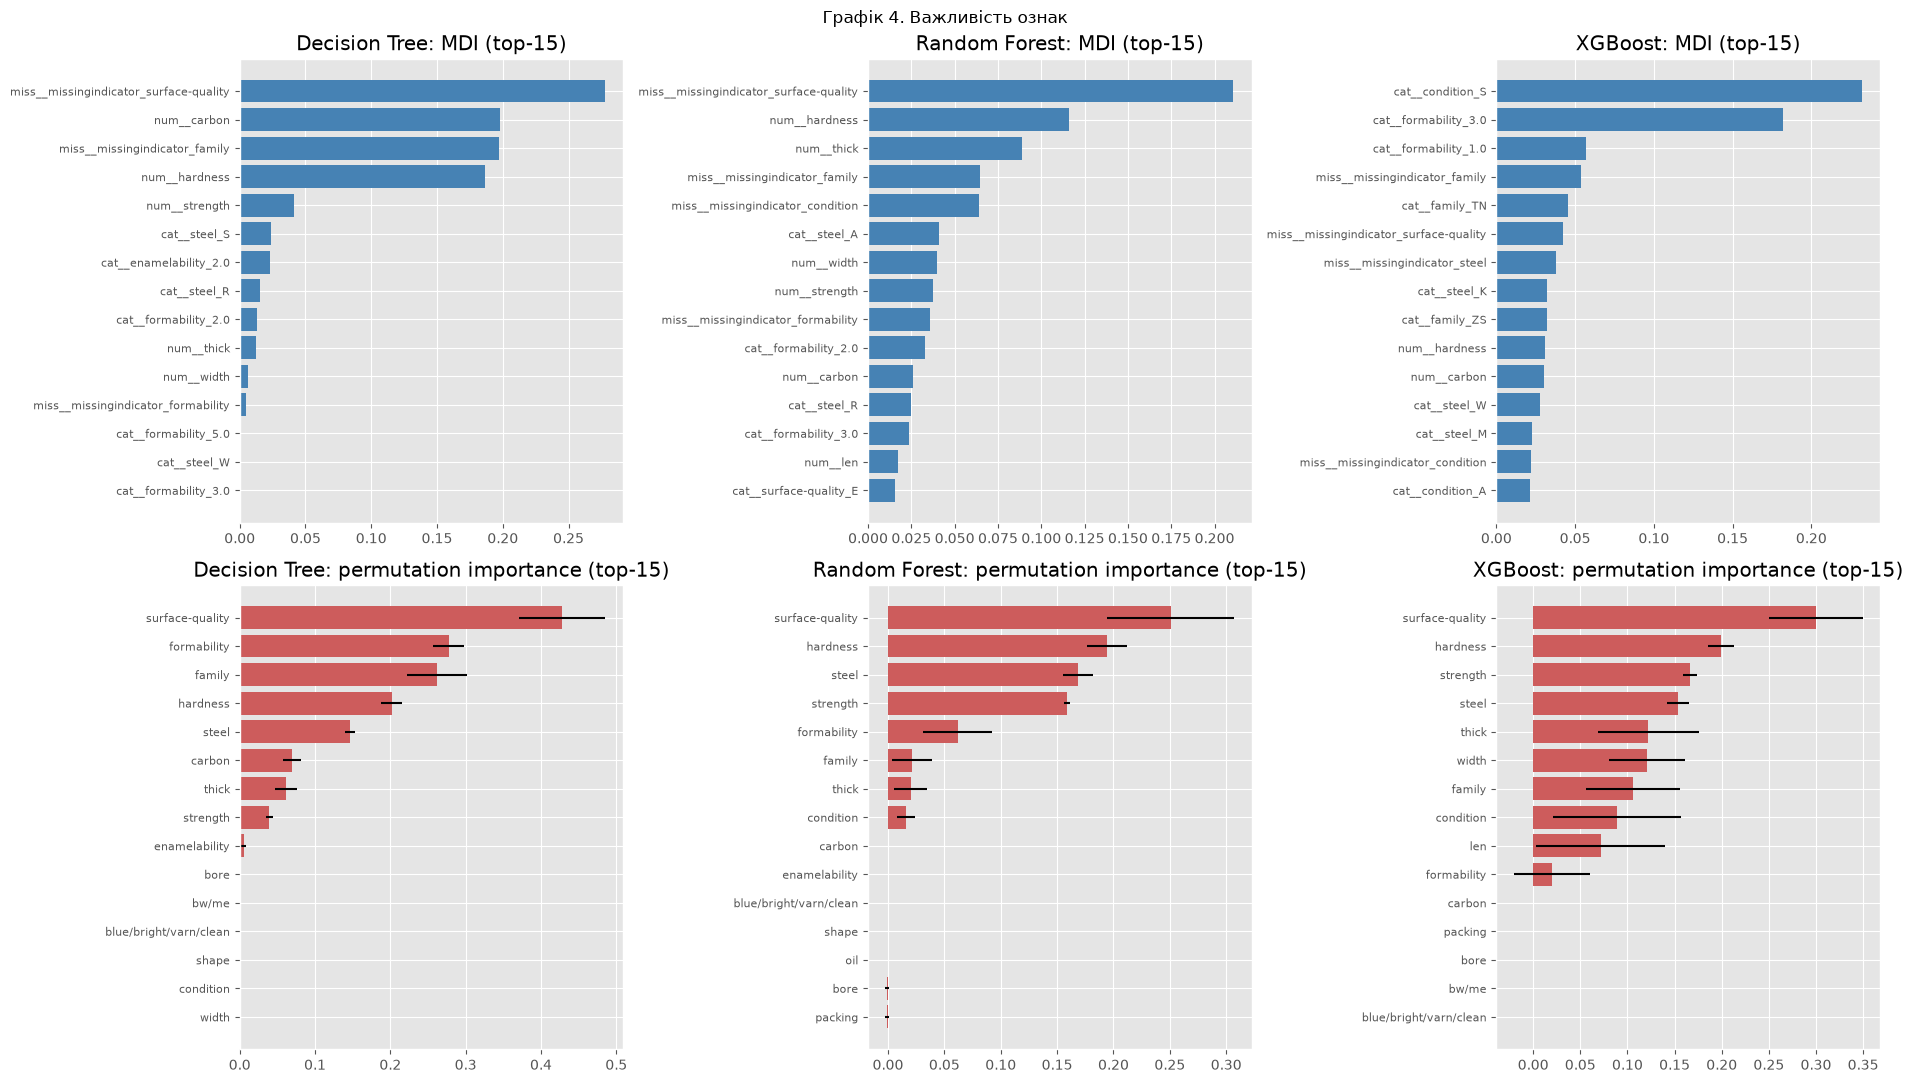

In [29]:
# Графік 4. MDI та permutation importance, top-15
perm_results = {}
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

for col, name in enumerate(MODELS):
    pipe = final_models[name]
    feature_names = pipe.named_steps['prep'].get_feature_names_out()
    mdi = pipe.named_steps['clf'].feature_importances_
    top = np.argsort(mdi)[::-1][:15][::-1]
    axes[0, col].barh(range(15), mdi[top], color='steelblue')
    axes[0, col].set_yticks(range(15))
    axes[0, col].set_yticklabels([feature_names[i] for i in top], fontsize=8)
    axes[0, col].set_title(f'{MODEL_NAMES[name]}: MDI (top-15)')

    perm = permutation_importance(pipe, X_test, y_test, scoring='f1_macro',
                                  n_repeats=10, random_state=SEED)
    perm_results[name] = perm
    top_p = np.argsort(perm.importances_mean)[::-1][:15][::-1]
    axes[1, col].barh(range(len(top_p)), perm.importances_mean[top_p],
                      xerr=perm.importances_std[top_p], color='indianred')
    axes[1, col].set_yticks(range(len(top_p)))
    axes[1, col].set_yticklabels([X_test.columns[i] for i in top_p], fontsize=8)
    axes[1, col].set_title(f'{MODEL_NAMES[name]}: permutation importance (top-15)')

plt.suptitle('Графік 4. Важливість ознак')
plt.tight_layout()
plt.show()

In [30]:
# Чи потрапили індикатори пропусків у top-15 за MDI
rows = []
for name in MODELS:
    pipe = final_models[name]
    feature_names = pipe.named_steps['prep'].get_feature_names_out()
    mdi = pipe.named_steps['clf'].feature_importances_
    top15 = [feature_names[i] for i in np.argsort(mdi)[::-1][:15]]
    indicators = [f for f in top15 if 'missingindicator' in f]
    rows.append({'Модель': MODEL_NAMES[name],
                 'Індикаторів у top-15': len(indicators),
                 'Сумарна вага індикаторів (MDI)': round(float(
                     mdi[[i for i, f in enumerate(feature_names) if 'missingindicator' in f]].sum()), 3),
                 'Індикатори в top-15': ', '.join(i.replace('miss__missingindicator_', '') for i in indicators)})
pd.DataFrame(rows)

,Модель,Індикаторів у top-15,Сумарна вага індикаторів (MDI),Індикатори в top-15
0,Decision Tree,3,0.480,"surface-quality, family, formability"
1,Random Forest,4,0.405,"surface-quality, family, condition, formability"
2,XGBoost,4,0.182,"family, surface-quality, steel, condition"


In [31]:
# Узгодженість MDI та permutation importance: порівняння топ-5 у початкових ознаках
for name in MODELS:
    pipe = final_models[name]
    feature_names = pipe.named_steps['prep'].get_feature_names_out()
    mdi = pipe.named_steps['clf'].feature_importances_
    # зводимо оброблені ознаки до початкових (прибираємо префікси і суфікси one-hot)
    base = []
    for f in feature_names:
        f = f.split('__', 1)[1]
        f = f.replace('missingindicator_', '')
        if f not in X.columns:
            f = max([c for c in X.columns if f.startswith(c)], key=len, default=f)
        base.append(f)
    mdi_by_feature = pd.Series(mdi, index=base).groupby(level=0).sum()
    perm_by_feature = pd.Series(perm_results[name].importances_mean, index=X_test.columns)
    print(f'{MODEL_NAMES[name]}:')
    print('   MDI top-5        :', list(mdi_by_feature.sort_values(ascending=False).head(5).index))
    print('   Permutation top-5:', list(perm_by_feature.sort_values(ascending=False).head(5).index))

Decision Tree:
   MDI top-5        : ['surface-quality', 'carbon', 'family', 'hardness', 'strength']
   Permutation top-5: ['surface-quality', 'formability', 'family', 'hardness', 'steel']
Random Forest:
   MDI top-5        : ['surface-quality', 'hardness', 'steel', 'formability', 'family']
   Permutation top-5: ['surface-quality', 'hardness', 'steel', 'strength', 'formability']
XGBoost:
   MDI top-5        : ['condition', 'formability', 'steel', 'family', 'surface-quality']
   Permutation top-5: ['surface-quality', 'hardness', 'strength', 'steel', 'thick']


**Висновок за графіком 4.**

**Чи потрапили індикатори пропусків у top-15 за MDI?** Так, і дуже помітно:

| Модель | Індикаторів у top-15 | Сумарна вага MDI | Які саме |
|---|---|---|---|
| Decision Tree | 3 | **0.480** | surface-quality, family, formability |
| Random Forest | 4 | 0.405 | surface-quality, family, condition, formability |
| XGBoost | 4 | 0.182 | family, surface-quality, steel, condition |

У дерева й лісу **майже половина всієї важливості** припадає на індикатори пропусків. Це повністю узгоджується
з аналізом механізму пропусків: ті самі ознаки (`family`, `surface-quality`, `condition`), для яких хі-квадрат
показав сильну залежність пропуску від класу, тепер є найважливішими. Інформативною є не величина ознаки,
а сам факт її наявності.

**Наскільки узгоджуються MDI та permutation importance?** Частково. `surface-quality` є в топі обох метрик
в усіх трьох моделей. Але є й розбіжності: у дерева MDI ставить на друге місце `carbon`, а permutation
натомість висуває `formability`; у XGBoost MDI віддає перевагу `condition` і `formability`, тоді як permutation
ставить на перші місця `surface-quality` і `hardness`.

**Чому MDI зміщена.** MDI рахує, скільки разів ознака використовувалась для розділення і наскільки зменшувала
неоднорідність **під час навчання**. Ознаки з великою кількістю унікальних значень (у нас це числові `carbon`,
`hardness`, `thick`, `width`) мають набагато більше можливих порогів розбиття, тому випадково отримують вищий
бал навіть без реальної прогностичної сили. Permutation importance вимірює інше: наскільки падає якість
**на нових даних**, якщо ознаку зіпсувати, тому вона чесніша, хоч і занижує важливість корельованих ознак
(модель компенсує зіпсовану ознаку її дублікатом).

**Чому важливості відрізняються між моделями.** Одне дерево обирає одну конкретну ознаку в корені й більше
до її дублікатів не повертається, тому вся важливість концентрується на кількох ознаках. Випадковий ліс на
кожному розбитті бачить лише випадкову підмножину ознак (`max_features='sqrt'`), тому важливість
розмазується між корельованими ознаками. XGBoost будує дерева послідовно на залишках помилок, тому перші
дерева забирають основний сигнал, а наступні зосереджуються на рідкісних випадках, і розподіл важливості
виходить ще іншим.

## 3.8 Аналіз розбіжностей між моделями

Об'єкт вважається об'єктом розбіжності, якщо прогнози трьох фінальних моделей не всі однакові.

In [32]:
preds = {name: final_models[name].predict(X_test) for name in MODELS}
disagree_mask = ~((preds['DT'] == preds['RF']) & (preds['RF'] == preds['XGB']))
disagree_idx = np.where(disagree_mask)[0]
print('Об\'єктів розбіжності в тестовій вибірці:', len(disagree_idx))

Об'єктів розбіжності в тестовій вибірці: 1


In [33]:
decode = lambda arr: label_encoder.inverse_transform(np.asarray(arr))

if len(disagree_idx) >= 3:
    source = 'тестова вибірка'
    table7 = pd.DataFrame({
        'Об\'єкт': [f'#{X_test.index[i]}' for i in disagree_idx],
        'Справжній клас': decode(y_test[disagree_idx]),
        'Decision Tree': decode(preds['DT'][disagree_idx]),
        'Random Forest': decode(preds['RF'][disagree_idx]),
        'XGBoost': decode(preds['XGB'][disagree_idx]),
        'Джерело': source,
    })
else:
    # доповнюємо out-of-fold прогнозами на тренувальній вибірці
    oof = {name: cross_val_predict(build_pipeline(name, True, studies[name].best_params),
                                   X_train, y_train, cv=outer) for name in MODELS}
    oof_mask = ~((oof['DT'] == oof['RF']) & (oof['RF'] == oof['XGB']))
    oof_idx = np.where(oof_mask)[0]
    print('Додатково знайдено об\'єктів розбіжності серед out-of-fold прогнозів:', len(oof_idx))
    table7 = pd.DataFrame({
        'Об\'єкт': ([f'#{X_test.index[i]}' for i in disagree_idx]
                   + [f'#{X_train.index[i]} (OOF)' for i in oof_idx]),
        'Справжній клас': np.concatenate([decode(y_test[disagree_idx]), decode(y_train[oof_idx])]),
        'Decision Tree': np.concatenate([decode(preds['DT'][disagree_idx]), decode(oof['DT'][oof_idx])]),
        'Random Forest': np.concatenate([decode(preds['RF'][disagree_idx]), decode(oof['RF'][oof_idx])]),
        'XGBoost': np.concatenate([decode(preds['XGB'][disagree_idx]), decode(oof['XGB'][oof_idx])]),
        'Джерело': (['тестова вибірка'] * len(disagree_idx)
                    + ['out-of-fold, тренувальна вибірка'] * len(oof_idx)),
    })

print('Таблиця 7. Об\'єкти розбіжності між прогнозами моделей')
table7.head(10)

Додатково знайдено об'єктів розбіжності серед out-of-fold прогнозів: 9
Таблиця 7. Об'єкти розбіжності між прогнозами моделей


,Об'єкт,Справжній клас,Decision Tree,Random Forest,XGBoost,Джерело
0,#746,3,3,2,2,тестова вибірка
1,#90 (OOF),U,U,3,3,"out-of-fold, тренувальна вибірка"
2,#585 (OOF),3,2,3,2,"out-of-fold, тренувальна вибірка"
3,#846 (OOF),3,3,3,2,"out-of-fold, тренувальна вибірка"
4,#22 (OOF),U,3,U,U,"out-of-fold, тренувальна вибірка"
5,#314 (OOF),3,3,3,2,"out-of-fold, тренувальна вибірка"
6,#682 (OOF),2,2,3,2,"out-of-fold, тренувальна вибірка"
7,#110 (OOF),3,2,3,3,"out-of-fold, тренувальна вибірка"
8,#17 (OOF),U,3,U,U,"out-of-fold, тренувальна вибірка"
9,#16 (OOF),U,U,3,3,"out-of-fold, тренувальна вибірка"


**Висновок за таблицею 7.**

*Що показано:* об'єкти, на яких прогнози трьох фінальних моделей не збігаються.

*Закономірність:* у тестовій вибірці знайдено лише **1** такий об'єкт зі 180. Це прямий прояв ефекту стелі:
моделі майже завжди дають однакову відповідь. Тому, як і передбачає методичка, таблицю доповнено
**out-of-fold** прогнозами на тренувальній вибірці (9 об'єктів), отриманими через `cross_val_predict`,
тобто кожен прогноз зроблено моделлю, яка цього об'єкта не бачила. Прогнози на власних тренувальних даних
для цього не використовувались, і джерело кожного рядка позначено в окремій колонці.

*Чому так:* розбіжності зосереджені навколо пар класів `3` проти `2` та `U` проти `3`. Це узгоджується
з матрицею плутанини: саме ці класи лежать найближче один до одного в просторі ознак.

*Як це впливає на вибір:* мала кількість розбіжностей означає, що ансамблювання трьох моделей (наприклад,
голосуванням) дало б майже той самий результат, що й одна модель, тобто ускладнення не окупається.

### Детальний аналіз одного об'єкта розбіжності

In [34]:
# беремо перший об'єкт розбіжності з тестової вибірки (якщо такі є)
case_pos = disagree_idx[0] if len(disagree_idx) else None
case_from_test = case_pos is not None

if case_from_test:
    case_X = X_test.iloc[[case_pos]]
    case_y = y_test[case_pos]
else:
    case_pos = oof_idx[0]
    case_X = X_train.iloc[[case_pos]]
    case_y = y_train[case_pos]

print('Об\'єкт:', case_X.index[0], '| справжній клас:', label_encoder.classes_[case_y])
print('Джерело:', 'тестова вибірка' if case_from_test else 'тренувальна вибірка (out-of-fold)')

# 1. початкові значення ознак і чим заповнено пропуски
prep = final_models['DT'].named_steps['prep']
imputed = pd.DataFrame(prep.transform(case_X), columns=prep.get_feature_names_out())

rows = []
for col in X.columns:
    raw_value = case_X.iloc[0][col]
    is_missing = pd.isna(raw_value)
    if is_missing:
        if col in NUMERIC:
            filled = imputed[f'num__{col}'].iloc[0]
        else:
            cat_cols = [c for c in imputed.columns if c.startswith(f'cat__{col}_')]
            active = [c for c in cat_cols if imputed[c].iloc[0] == 1]
            filled = active[0].replace(f'cat__{col}_', '') if active else '?'
    else:
        filled = raw_value
    rows.append({'Ознака': col, 'Початкове значення': 'ПРОПУСК' if is_missing else raw_value,
                 'Значення після імпутації': filled, 'Було пропущено': is_missing})
pd.DataFrame(rows)

Об'єкт: 746 | справжній клас: 3
Джерело: тестова вибірка


,Ознака,Початкове значення,Значення після імпутації,Було пропущено
0,family,ПРОПУСК,TN,True
1,steel,V,V,False
2,carbon,0,0,False
3,hardness,0,0,False
4,condition,S,S,False
5,formability,2.0,2.0,False
6,strength,0,0,False
7,surface-quality,ПРОПУСК,E,True
8,enamelability,1.0,1.0,False
9,bw/me,ПРОПУСК,B,True


In [35]:
# 2. Ймовірності класів у трьох моделей
proba = pd.DataFrame({MODEL_NAMES[name]: final_models[name].predict_proba(case_X)[0]
                      for name in MODELS}, index=label_encoder.classes_)
print('Ймовірності класів для цього об\'єкта:')
proba.round(3)

Ймовірності класів для цього об'єкта:


,Decision Tree,Random Forest,XGBoost
1,0.0,0.000,0.030
2,0.0,0.507,0.825
3,1.0,0.493,0.126
5,0.0,0.000,0.014
U,0.0,0.000,0.005


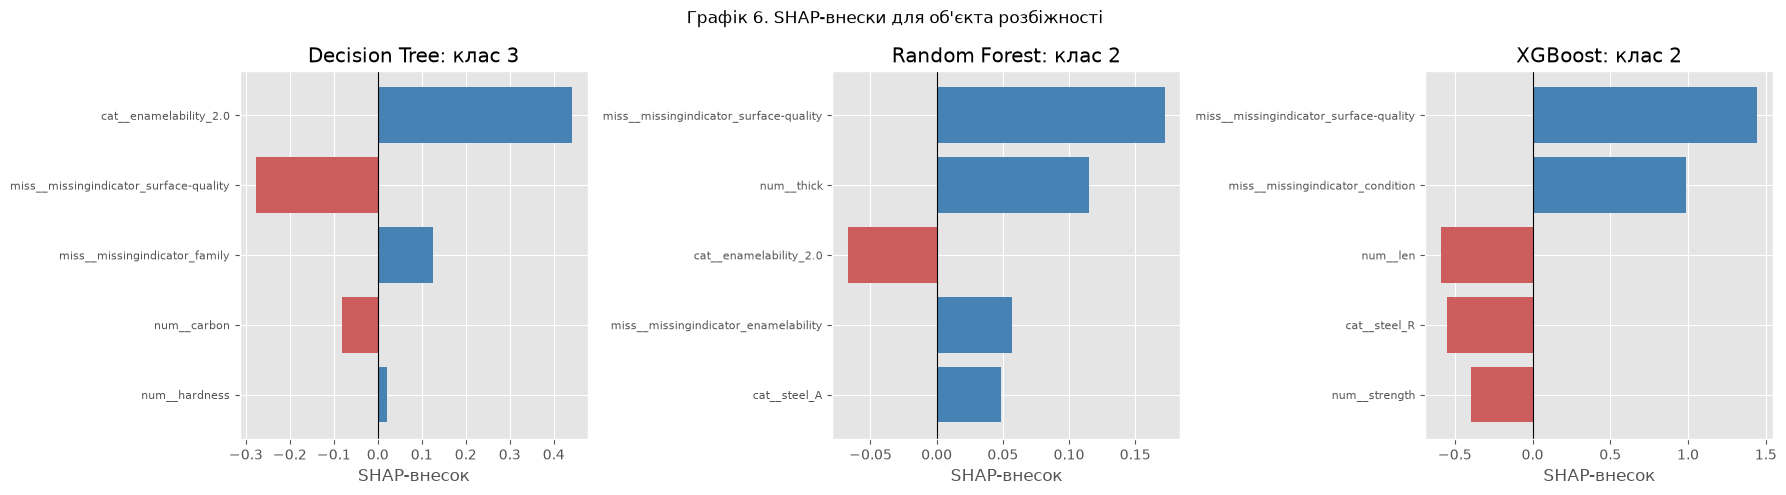

Decision Tree   [('cat__enamelability_2.0', 0.441), ('miss__missingindicator_surface-quality', -0.278), ('miss__missingindicator_family', 0.127), ('num__carbon', -0.081), ('num__hardness', 0.021)]
Random Forest   [('miss__missingindicator_surface-quality', 0.172), ('num__thick', 0.115), ('cat__enamelability_2.0', -0.067), ('miss__missingindicator_enamelability', 0.057), ('cat__steel_A', 0.049)]
XGBoost         [('miss__missingindicator_surface-quality', 1.446), ('miss__missingindicator_condition', 0.985), ('num__len', -0.589), ('cat__steel_R', -0.548), ('num__strength', -0.395)]


In [36]:
# 3. SHAP-значення: топ-5 ознак за модулем внеску у прогнозований клас
case_proc = prep.transform(case_X)
feature_names = prep.get_feature_names_out()

shap_top = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, MODELS):
    model = final_models[name].named_steps['clf']
    case_proc_model = final_models[name].named_steps['prep'].transform(case_X)
    explainer = shap.TreeExplainer(model)
    shap_values = np.array(explainer.shap_values(case_proc_model))   # (1, n_features, n_classes)
    predicted_class = int(final_models[name].predict(case_X)[0])
    contrib = shap_values[0, :, predicted_class]
    top = np.argsort(np.abs(contrib))[::-1][:5]
    shap_top[name] = [(feature_names[i], round(float(contrib[i]), 3)) for i in top]

    ax.barh(range(5), contrib[top][::-1],
            color=['indianred' if v < 0 else 'steelblue' for v in contrib[top][::-1]])
    ax.set_yticks(range(5))
    ax.set_yticklabels([feature_names[i] for i in top][::-1], fontsize=8)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{MODEL_NAMES[name]}: клас {label_encoder.classes_[predicted_class]}')
    ax.set_xlabel('SHAP-внесок')

plt.suptitle('Графік 6. SHAP-внески для об\'єкта розбіжності')
plt.tight_layout()
plt.show()

for name in MODELS:
    print(f'{MODEL_NAMES[name]:15s}', shap_top[name])

**Висновок за графіком 6 (детальний аналіз об'єкта розбіжності).**

*Що показано:* об'єкт **#746** із тестової вибірки, справжній клас `3`. Дерево передбачило `3` (правильно),
а ліс і XGBoost передбачили `2` (помилка).

*Стан об'єкта:* 6 із 18 ознак пропущені (`family`, `surface-quality`, `bw/me`, `blue/bright/varn/clean`,
`oil`, `packing`) і заповнені модою: `family` стало `TN`, `surface-quality` стало `E`, `oil` стало `Y`.
Тобто третина ознак об'єкта це не виміряні значення, а підставлені.

*Ймовірності класів:*

| Клас | Decision Tree | Random Forest | XGBoost |
|---|---|---|---|
| 2 | 0.000 | 0.507 | 0.825 |
| 3 | **1.000** | 0.493 | 0.126 |

Випадковий ліс фактично кинув монетку: 0.507 проти 0.493, тобто з 150 дерев рівно половина проголосувала
за кожен клас. Дерево ж абсолютно впевнене, бо один шлях у дереві дає єдиний листок.

*SHAP-внески у прогнозований клас (топ-3):*

- **Decision Tree:** `enamelability_2.0` (+0.441), `missingindicator_surface-quality` (-0.278), `missingindicator_family` (+0.127);
- **Random Forest:** `missingindicator_surface-quality` (+0.172), `thick` (+0.115), `enamelability_2.0` (-0.067);
- **XGBoost:** `missingindicator_surface-quality` (+1.446), `missingindicator_condition` (+0.985), `len` (-0.589).

*Чому моделі розійшлися:*

1. **Різні опори.** Дерево спирається передусім на значення `enamelability`, а ансамблі на **індикатори пропусків**.
   Той самий індикатор `surface-quality` штовхає дерево від його класу (-0.278), а XGBoost до його класу (+1.446).
2. **Жорсткі пороги проти усереднення.** Одне дерево дає категоричний прогноз (ймовірність 1.0), бо об'єкт
   потрапляє в один листок. Ліс усереднює 150 дерев, які «бачили» різні підмножини ознак, і через це отримує
   майже рівний розподіл голосів.
3. **Близькість до межі.** Об'єкт лежить рівно на межі між класами `2` і `3`, що підтверджується ймовірностями
   лісу. У таких випадках результат вирішує не сила моделі, а дрібні деталі, зокрема те, якими значеннями
   заповнено пропуски. Фактично модель приймає рішення частково за вигаданими (імпутованими) даними.

*Як це впливає на вибір:* на об'єктах із великою часткою пропусків варто або відмовлятись від автоматичного
рішення (поріг впевненості), або використовувати нативну обробку NaN, щоб модель не спиралась на підставлені значення.

## Висновок

1. **Найкраща модель.** За macro F1 на крос-валідації найкращим виявилось просте **дерево рішень**
   (0.9903 ± 0.0088 у варіанті B), випадковий ліс дав 0.9864 ± 0.0125, XGBoost 0.9842 ± 0.0142. Проте
   скоригований t-тест Наде-Бенжіо показав, що різниця між деревом і лісом **статистично не значуща**
   (d = 0.0038, p = 0.52), тобто на цьому датасеті всі три моделі еквівалентні за якістю.

2. **Індикатори пропусків.** Вони дали найбільший ефект у всій роботі: приріст macro F1 склав від +0.057
   до +0.068 для всіх трьох моделей, а стандартне відхилення зменшилось у кілька разів. Це узгоджується
   з аналізом механізму пропусків (пропуски не MCAR: для `family` p = 4.6e-99) та з важливостями ознак
   (у дерева на індикатори припадає 0.480 сумарної MDI-ваги). Формально значущим приріст виявився лише
   для випадкового лісу (p = 0.0002), бо у двох інших моделей дисперсія різниць утричі більша.

3. **Оптимістичне зміщення.** `best_value` (0.895-0.923) виявився нижчим за вкладену крос-валідацію
   (0.979-0.985), але це наслідок різних протоколів: внутрішня крос-валідація має лише 3 блоки через клас
   із 6 об'єктами. Коректне порівняння дає оцінка налаштованої моделі на тих самих блоках, 0.9903 проти
   0.9791 у вкладеній крос-валідації, тобто зміщення +0.011. Висновок незмінний: `best_value` не можна
   подавати як оцінку якості моделі.

4. **Приріст від оптимізації** практично нульовий: 0.0000 у дерева, +0.0005 у лісу і навіть -0.0054 у XGBoost.
   Причина в ефекті стелі: типові гіперпараметри вже дають accuracy 0.99, і покращувати нема чого, а Optuna
   максимізувала шумнішу 3-блочну метрику.

5. **Найскладніший клас** це клас `1`: 8 об'єктів у всьому датасеті, 6 у навчанні та 2 в тесті. Саме на ньому
   сталася єдина помилка фінальної моделі на тесті (recall 0.50), і саме він коштував 0.07 macro F1.
   Усі інші класи розпізнаються з recall 1.00.

6. **Аналіз розбіжностей** показав, що моделі майже завжди згодні: на 180 тестових об'єктів припав лише один
   випадок незгоди. Детальний розбір об'єкта #746 виявив, що розбіжність виникає на об'єкті з 6 пропущеними
   ознаками, який лежить точно на межі класів `2` і `3` (ліс дав 0.507 проти 0.493), причому ансамблі
   спираються на індикатори пропусків, а дерево на імпутоване значення `enamelability`.

7. **Що обрати для практичного використання.** Я б обрав **дерево рішень**: воно дає не гіршу якість
   (різниця з ансамблями статистично не значуща), навчається за частки секунди замість десятків секунд,
   і його рішення можна показати технологу у вигляді явних правил. Випадковий ліс варто брати, якщо потрібна
   калібрована впевненість (його ймовірності чесніше показують межові випадки, як у прикладі #746),
   а XGBoost тут переваг не дає і при цьому найдорожчий у навчанні та підборі параметрів.

## Контрольні питання

**1. Чим випадковий ліс відрізняється від окремого дерева з погляду зміщення і дисперсії? Роль декореляції.**
Глибоке дерево має мале зміщення, але величезну дисперсію: зміна кількох об'єктів у вибірці повністю змінює
структуру дерева. Ліс усереднює багато таких дерев, і дисперсія середнього падає приблизно в N разів, якщо
дерева незалежні. Зміщення при цьому майже не зростає. Але дерева, навчені на бутстреп-вибірках тих самих даних,
корельовані, а дисперсія середнього корельованих величин обмежена знизу їхньою коваріацією. Тому ліс додатково
**декорелює** дерева, пропонуючи кожному розбиттю лише випадкову підмножину ознак (`max_features`): дерева стають
різноманітнішими, кореляція падає, і усереднення працює ефективніше.

**2. Різниця між бустингом і беггінгом. Хто схильніший до перенавчання зі зростанням кількості дерев?**
Беггінг (ліс) навчає дерева **паралельно й незалежно** на бутстреп-вибірках і усереднює їх, тобто бореться
з **дисперсією**. Бустинг (XGBoost) навчає дерева **послідовно**, кожне наступне виправляє помилки попередніх,
тобто бореться зі **зміщенням**. Зі зростанням кількості дерев ліс не перенавчається: додавання дерев лише
точніше наближає середнє. Бустинг перенавчається, бо кожне нове дерево цілеспрямовано підганяється під залишки,
зокрема під шум; тому в ньому потрібні `learning_rate`, `subsample` і рання зупинка.

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy при дисбалансі? Macro проти weighted.**
У нас клас `3` становить 76% даних, тому модель, що завжди відповідає `3`, отримає accuracy 0.76, не вміючи нічого.
Macro F1 усереднює F1 по класах **з однаковою вагою**, тому провал на рідкісному класі одразу видно; balanced
accuracy робить те саме з recall. Weighted-усереднення зважує класи за їхнім розміром, тому результат майже
дорівнює accuracy і знову приховує рідкісні класи. У нашій роботі різниця наочна: на тесті accuracy = 0.9944,
а macro F1 = 0.9326 через одну помилку на класі з двох об'єктів.

**4. MCAR, MAR, MNAR. Коли індикатори найкорисніші? Чи можна відрізнити MAR від MNAR за даними?**
MCAR: ймовірність пропуску не залежить ні від чого. MAR: залежить лише від **спостережуваних** ознак.
MNAR: залежить від самого відсутнього значення або від неспостережуваних чинників. Індикатори найкорисніші
при MAR і особливо MNAR, тобто коли сам факт пропуску несе інформацію; при MCAR вони додають лише шум.
Відрізнити MAR від MNAR за наявними даними **неможливо**, бо для цього треба було б знати саме ті значення,
яких немає. Висновок можна зробити лише з предметних знань: у нашому датасеті документація прямо каже, що
частина ознак не застосовна до певних типів сталі, тобто пропуск структурний.

**5. Де може виникнути витік даних при імпутації та оптимізації і як цьому запобігти?**
Класичні місця: (а) `fit_transform` імпутера на всьому датасеті до поділу (медіана вбирає тестові значення);
(б) масштабування або кодування до крос-валідації; (в) передача в Optuna заздалегідь оброблених даних;
(г) використання тестової вибірки в цільовій функції або для ранньої зупинки. Запобігання: всі навчувані
перетворення всередині `Pipeline`, у крос-валідацію і в Optuna передається **весь пайплайн**, тест відкривається
один раз у кінці. Саме так побудована ця робота.

**6. Чому best_value зміщений? Як працює вкладена крос-валідація і що саме вона оцінює?**
Ми обираємо максимум серед 30 зашумлених оцінок, а максимум шумних величин систематично більший за їхнє
істинне середнє, тобто `best_value` містить «удачу» конкретного розбиття. Вкладена крос-валідація розриває
цей зв'язок: у зовнішньому циклі кожен блок жодного разу не бере участі в підборі параметрів, бо `tune()`
викликається лише на його тренувальній частині. Важливо, що зовнішній цикл оцінює не фіксовану модель,
а **всю процедуру** «підібрати гіперпараметри і навчити модель», бо на різних блоках знайдені параметри різні.

**7. Чому звичайний парний t-тест не підходить і що виправляє поправка Наде-Бенжіо?**
Блоки крос-валідації перетинаються тренувальними даними, тому різниці метрик на блоках **корельовані**,
а звичайний t-тест припускає незалежність і через це занижує дисперсію та завищує значущість. Поправка
Наде-Бенжіо замінює `var/n` на `var * (1/(k*r) + n_test/n_train)`, додаючи доданок, що враховує перетин вибірок.
У нашій роботі це змінило p для дерева з 0.00075 на 0.069, тобто з «значуще» на «не значуще».

**8. MDI проти permutation importance. Вплив корельованих ознак.**
MDI рахується під час навчання як сумарне зменшення неоднорідності, тому вона безкоштовна, але зміщена
на користь ознак із багатьма унікальними значеннями (більше можливих порогів) і відображає поведінку на
**тренувальних** даних. Permutation importance вимірює падіння метрики на **нових** даних при псуванні ознаки.
Корельовані ознаки впливають по-різному: MDI «розмазує» важливість між ними (особливо в лісі), а permutation
занижує важливість обох, бо модель компенсує зіпсовану ознаку її дублікатом.

**9. Що таке SHAP-значення, яку властивість вони задовольняють, чим відрізняються від глобальної важливості?**
SHAP-значення це внески окремих ознак у конкретний прогноз, обчислені як усереднені граничні внески
по всіх порядках додавання ознак (значення Шеплі з теорії кооперативних ігор). Головна властивість це
**адитивність**: сума внесків усіх ознак плюс базове значення дорівнює прогнозу моделі для цього об'єкта.
Глобальна важливість каже, які ознаки важливі для моделі **в середньому**, а SHAP пояснює **один конкретний
випадок** і показує не лише силу, а й напрям впливу (за чи проти класу), як у нашому розборі об'єкта #746.

**10. Як XGBoost обробляє пропуски нативно (sparsity-aware split finding)?**
У кожному вузлі XGBoost шукає поріг лише за спостережуваними значеннями, а потім перевіряє два варіанти:
відправити всі пропуски ліворуч або праворуч. Обирається той, що дає більший приріст. Цей напрям
запам'ятовується як **default direction** вузла, і на етапі прогнозу об'єкт із пропуском іде саме туди.
Тобто модель вчиться оптимальному поводженню з пропусками безпосередньо з даних, не вигадуючи значень.

**11. Переваги Optuna перед GridSearchCV і RandomizedSearchCV.**
GridSearchCV перебирає всі комбінації сітки, і їхня кількість зростає експоненційно з числом параметрів;
RandomizedSearchCV пробує випадкові точки, не використовуючи інформацію з попередніх спроб. Optuna застосовує
**TPE-семплер**: будує ймовірнісні моделі розподілів параметрів для вдалих і невдалих випробувань і наступну
точку обирає там, де відношення цих щільностей найвигідніше, тобто навчається на історії. Додатково вона вміє
**прунінг** (достроково зупиняти безнадійні випробування), підтримує неперервні та логарифмічні шкали,
умовні простори пошуку і дає готові інструменти аналізу, якими ми скористались у графіку 3.